# NHAMCS-ED 2022 — Multi-Label Laboratory, Imaging, and Medication Outcomes

**Final project starter notebook** — data ingestion, variable audit, grouped outcome construction, co-occurrence, baseline benchmark (Binary Relevance, Classifier Chains, RAkEL, ML-kNN), and SHAP.

## Alur analisis — ringkasan mudah

**Tujuan:** membandingkan beberapa model untuk memprediksi tiga jenis layanan yang tercatat pada satu kunjungan IGD. Setiap baris data mewakili satu kunjungan dari NHAMCS-ED 2022.

### 1. Data yang dipakai
Notebook membaca file `data/ed2022.csv` (atau file lain yang ditentukan di konfigurasi). Data berisi karakteristik pasien, kedatangan, triase, tanda vital, dan layanan yang diberikan/dipesan. Kolom-kolomnya banyak berupa kode; arti dan kode khusus diperiksa di `codebook.pdf`. `RFV1`–`RFV5` adalah kode alasan kunjungan, bukan catatan keluhan dalam bentuk kalimat.

### 2. Fitur yang dipertimbangkan
Fitur adalah informasi yang diberikan ke model sebagai masukan. Kelompok awal yang dipertimbangkan: demografi (`AGE`, `SEX`, `RACERETH`), datang dengan ambulans (`ARREMS`), urgensi triase (`IMMEDR`), tanda vital awal (`TEMPF`, `PULSE`, `RESPR`, `BPSYS`, `BPDIAS`, `POPCT`), sumber pembayaran (`PAYTYPER`), dan riwayat komorbiditas.

Alasannya: kelompok tersebut menggambarkan kondisi dan konteks pasien. `PAYTYPER` dan komorbiditas masih perlu ditinjau apakah sudah tersedia pada waktu prediksi. Keluhan bebas belum dimasukkan karena file menyediakan kode `RFV`, bukan teks. Sel EDA membantu memeriksa distribusi dan pola awal; EDA saja tidak membuktikan fitur penting atau aman dari kebocoran.

### 3. Target yang diprediksi
Target adalah keluaran yang ingin diprediksi. Notebook membentuk tiga label 0/1 yang bisa aktif bersamaan:

- **Laboratory:** 1 bila setidaknya satu tes laboratorium/tes terkait yang terdaftar tercatat;
- **Imaging:** 1 bila setidaknya satu layanan pencitraan tercatat;
- **Medication:** 1 bila `MED` menyatakan obat/imunisasi diberikan di IGD atau diresepkan saat pulang.

Contoh: satu kunjungan dapat memiliki `Laboratory=1`, `Imaging=1`, dan `Medication=0`. Label ini bersifat kelompok, jadi tidak menjelaskan tes atau obat spesifik. NHAMCS mencatat layanan yang dipesan **atau diberikan** dan tidak menyediakan waktu pemesanan yang pasti.

### 4. Persiapan dan evaluasi
Kode khusus dipertahankan atau ditangani sesuai codebook; label kelompok negatif hanya diberikan bila komponen yang diperlukan teramati. Data kemudian dibagi menjadi data latih dan uji. Model belajar dari data latih; hasilnya dibandingkan pada data uji yang tidak dipakai untuk melatih model.

**Catatan populasi:** saat ini notebook belum membatasi data ke pasien dewasa ≥18 tahun. Jika itu populasi penelitian yang dipilih, filter `AGE >= 18` perlu diterapkan sebelum EDA dan pembentukan target.

### 5. Mengapa model-model ini?

| Model | Gagasan sederhana | Alasan dibandingkan |
|---|---|---|
| Binary Relevance | Melatih satu model terpisah untuk tiap label. | Baseline sederhana; mudah melihat kinerja Laboratory, Imaging, dan Medication satu per satu. |
| Classifier Chains | Memprediksi label berurutan; prediksi label sebelumnya menjadi masukan bagi label berikutnya. | Menguji apakah keterkaitan antar keluaran membantu. Urutan dapat memengaruhi hasil. |
| RAkELd | Membagi label menjadi kelompok kecil lalu mempelajari kombinasi label. | Pembanding yang mempertimbangkan kombinasi label; dengan tiga label, ukuran kelompok 2 dipakai agar bukan satu kelompok tunggal. |
| ML-kNN | Memperkirakan label dari tetangga dengan fitur paling mirip. | Pembanding berbasis kemiripan, tanpa asumsi hubungan linear seperti regresi logistik. |

Metrik F1 micro/macro/samples, Hamming loss, dan subset accuracy merangkum kinerja dari sudut berbeda. Bagian SHAP kemudian menjelaskan pola yang dipakai model Binary Relevance; itu bukan sebab-akibat atau rekomendasi klinis.

**Sebelum menafsirkan hasil:** `CONFIRM_FEATURE_TIMING` masih `False`. Tentukan dahulu waktu prediksi dan pastikan fitur sudah tersedia saat itu.

**Source:** [CDC NHAMCS 2022](https://www.cdc.gov/nchs/nhamcs/documentation/index.html) · [2022 technical documentation](https://ftp.cdc.gov/pub/health_statistics/nchs/dataset_documentation/NHAMCS/doc22-ed-508.pdf) · [2022 survey form](https://www.cdc.gov/nchs/data/nhamcs/2022-NHAMCS-ED-PRF-sample-card-508.pdf).

> **Important:** Survey labels denote tests **ordered or provided**. They do not establish the ordering time. This notebook is an **offline retrospective benchmark**, *not* a clinical decision-support system or validated prospective triage predictor. Medication is captured as administered/prescribed, which is a distinct outcome from diagnostic orders.

## 1. Dependencies and configuration

In [35]:
# Run once; restart kernel if necessary
%pip -q install pandas numpy scipy scikit-learn matplotlib seaborn pyreadstat scikit-multilearn shap joblib requests

Note: you may need to restart the kernel to use updated packages.


In [36]:
from pathlib import Path
import re, zipfile, requests, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain
from sklearn.metrics import f1_score, hamming_loss, jaccard_score, classification_report, average_precision_score
from sklearn.base import clone
from skmultilearn.ensemble import RakelD
from scipy.sparse import issparse, csr_matrix
import joblib

SEED=42
DATA_DIR=Path('data'); DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)
ZIP_URL='https://ftp.cdc.gov/pub/Health_Statistics/NCHS/Dataset_Documentation/NHAMCS/stata/ed2022-stata.zip'
ZIP_PATH=DATA_DIR/'ed2022-stata.zip'
# Use the existing CSV; set None to load the official ZIP or provide a .dta/.csv/.sas7bdat path.
LOCAL_DATA=DATA_DIR/'ed2022.csv'
DOWNLOAD=False
# For faster development; None means all records
SAMPLE_N=None


## 2. Download and load public use data

In [37]:
if LOCAL_DATA is None:
    if not ZIP_PATH.exists():
        if not DOWNLOAD: raise FileNotFoundError('Set LOCAL_DATA or DOWNLOAD=True')
        print('Downloading official CDC ZIP...')
        with requests.get(ZIP_URL, stream=True, timeout=90) as r:
            r.raise_for_status()
            with open(ZIP_PATH,'wb') as f:
                for chunk in r.iter_content(1024*1024):
                    if chunk: f.write(chunk)
    with zipfile.ZipFile(ZIP_PATH) as z:
        print('ZIP contents:', z.namelist()[:20])
        safe=[p for p in z.namelist() if p.lower().endswith('.dta') and not Path(p).is_absolute() and '..' not in Path(p).parts]
        if not safe: raise RuntimeError('No .dta found in archive. Inspect ZIP and set LOCAL_DATA manually.')
        member=safe[0]
        target=DATA_DIR/Path(member).name
        if not target.exists():
            with z.open(member) as src, target.open('wb') as dst:
                import shutil; shutil.copyfileobj(src,dst)
    dataset_path=target
else:
    if isinstance(LOCAL_DATA, bool):
        raise TypeError('LOCAL_DATA must be None or a path to a .dta, .csv, or .sas7bdat file; it cannot be True/False.')
    dataset_path=Path(LOCAL_DATA)
assert dataset_path.exists(),dataset_path
if dataset_path.suffix.lower()=='.dta':
    df=pd.read_stata(dataset_path, convert_categoricals=False)
elif dataset_path.suffix.lower()=='.csv':
    df=pd.read_csv(dataset_path,low_memory=False)
elif dataset_path.suffix.lower()=='.sas7bdat':
    df=pd.read_sas(dataset_path)
else: raise ValueError(f'Unsupported format: {dataset_path.suffix}')
df.columns=df.columns.str.upper().str.strip()
if SAMPLE_N is not None and len(df)>SAMPLE_N: df=df.sample(SAMPLE_N,random_state=SEED)
print('Shape',df.shape)
display(df.head(3));display(df.dtypes.value_counts())

Shape (16025, 913)


,VMONTH,VDAYR,ARRTIME,WAITTIME,LOV,AGE,AGER,AGEDAYS,RESIDNCE,SEX,...,RX30V3C2,RX30V3C3,RX30V3C4,SETTYPE,YEAR,CSTRATM,CPSUM,PATWT,EDWT,BOARDED
0,9,2,604,10,228,23,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,8.36413,-7
1,9,2,1053,40,319,15,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
2,9,2,1419,70,551,19,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7


float64    572
int64      298
str         43
Name: count, dtype: int64

## Exploratory data analysis — broad feature candidates
Run these cells after loading the data and before choosing model features. The inventory covers several plausible groups so you can compare them during EDA. These are not all automatically suitable predictors: check code meanings, special values, and whether each variable is available at the intended prediction time. Injury/circumstance and hospital-context fields especially need a timing and generalizability review.


### 1. Choose candidate columns


In [38]:
# Candidate feature inventory for EDA. Fields remain candidates until codes and timing are reviewed.
EDA_FEATURE_GROUPS = {
    'Demographics': ['AGE', 'AGER', 'SEX', 'ETHIM', 'RACERETH', 'RESIDNCE'],
    'Arrival / visit context': ['ARREMS', 'AMBTRANSFER', 'ARRTIME', 'VMONTH', 'VDAYR', 'EPISODE', 'SEEN72'],
    'Payment': ['PAYTYPER', 'PAYPRIV', 'PAYMCARE', 'PAYMCAID', 'PAYWKCMP', 'PAYSELF', 'PAYNOCHG', 'PAYOTH', 'PAYDK'],
    'Initial vital signs': ['TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT'],
    'Triage / symptom': ['IMMEDR', 'PAINSCALE', 'RFV1', 'RFV2', 'RFV3', 'RFV4', 'RFV5'],
    'Reported chronic conditions': ['ETOHAB', 'ALZHD', 'ASTHMA', 'CANCER', 'CEBVD', 'CKD', 'COPD', 'CHF', 'CAD', 'DEPRN', 'DIABTYP1', 'DIABTYP2', 'DIABTYP0', 'ESRD', 'HPE', 'EDHIV', 'HYPLIPID', 'HTN', 'OBESITY', 'OSA', 'OSTPRSIS', 'SUBSTAB', 'NOCHRON', 'TOTCHRON'],
    'Injury / visit circumstances — timing review': ['INJURY', 'INJPOISAD', 'INJURY72', 'INTENT15'],
    'Hospital context — generalizability review': ['REGION', 'MSA', 'CATRIAGE', 'ADVTRIAG', 'FASTTRAK', 'EDPRIM', 'EHRINSE'],
}

# Group individual codebook fields into the three requested multi-label outcomes.
# Laboratory includes blood/urine and other named diagnostic tests; EKG/cardiac
# monitoring are excluded because they are not laboratory tests.
TARGET_GROUPS = {
    'Laboratory': [
        'ABG', 'BAC', 'BMP', 'BNP', 'BUNCREAT', 'CARDENZ', 'CBC', 'CMP',
        'BLOODCX', 'TRTCX', 'URINECX', 'WOUNDCX', 'OTHCX', 'DDIMER',
        'ELECTROL', 'GLUCOSE', 'LACTATE', 'LFT', 'PTTINR', 'OTHERBLD',
        'HIVTEST', 'FLUTEST', 'PREGTEST', 'TOXSCREN', 'URINE', 'COVIDTEST',
        'COVIDANTIBODY',
    ],
    'Imaging': [
        'ANYIMAGE', 'XRAY', 'CATSCAN', 'CTAB', 'CTCHEST', 'CTHEAD', 'CTOTHER', 'CTUNK', 'MRI',
        'ULTRASND', 'OTHIMAGE',
    ],
    'Medication': ['MED'],
}

# Keep only columns present in this dataset. The derived outcomes are positive
# when any component service in that group was recorded as ordered/provided.
TARGET_GROUPS = {name: [col for col in cols if col in df.columns]
                 for name, cols in TARGET_GROUPS.items()}

def make_group_label(frame, columns):
    values = frame[columns]
    positive = values.eq(1).any(axis=1)
    fully_observed = values.isin([0, 1]).all(axis=1)
    # A documented positive wins; negative requires every component observed.
    return positive.astype(float).where(positive | fully_observed, np.nan)

EDA_Y = pd.DataFrame({name: make_group_label(df, cols)
                      for name, cols in TARGET_GROUPS.items()}, index=df.index)
eda_features = [(group, col) for group, cols in EDA_FEATURE_GROUPS.items()
                 for col in cols if col in df.columns]
eda_labels = list(EDA_Y.columns)
print(f'Rows: {len(df):,} | Columns: {len(df.columns):,}')
print('Candidate features found:', len(eda_features), '| Output labels:', eda_labels)
print('Source columns per output:', {name: cols for name, cols in TARGET_GROUPS.items()})
print('Feature groups:', {g: sum(col in df.columns for col in cols) for g, cols in EDA_FEATURE_GROUPS.items()})


Rows: 16,025 | Columns: 913
Candidate features found: 70 | Output labels: ['Laboratory', 'Imaging', 'Medication']
Source columns per output: {'Laboratory': ['ABG', 'BAC', 'BMP', 'BNP', 'BUNCREAT', 'CARDENZ', 'CBC', 'CMP', 'BLOODCX', 'TRTCX', 'URINECX', 'WOUNDCX', 'OTHCX', 'DDIMER', 'ELECTROL', 'GLUCOSE', 'LACTATE', 'LFT', 'PTTINR', 'OTHERBLD', 'HIVTEST', 'FLUTEST', 'PREGTEST', 'TOXSCREN', 'URINE', 'COVIDTEST', 'COVIDANTIBODY'], 'Imaging': ['ANYIMAGE', 'XRAY', 'CATSCAN', 'CTAB', 'CTCHEST', 'CTHEAD', 'CTOTHER', 'CTUNK', 'MRI', 'ULTRASND', 'OTHIMAGE'], 'Medication': ['MED']}
Feature groups: {'Demographics': 6, 'Arrival / visit context': 7, 'Payment': 9, 'Initial vital signs': 6, 'Triage / symptom': 7, 'Reported chronic conditions': 24, 'Injury / visit circumstances — timing review': 4, 'Hospital context — generalizability review': 7}


### 2. Check missing and special codes
Treat codes such as `-9`, `-8`, and `-7` according to each variable’s codebook definition; they do not all mean the same thing.


In [39]:
eda_quality = []
for group, col in eda_features:
    s = df[col]
    text = s.astype('string').str.strip()
    special = text.isin(['-9', '-8', '-7'])
    eda_quality.append({
        'group': group, 'feature': col, 'dtype': str(s.dtype),
        'blank_or_NA': int((s.isna() | text.eq('')).sum()),
        'codes_-9/-8/-7': int(special.sum()),
        'distinct_values': int(s.nunique(dropna=True)),
    })
display(pd.DataFrame(eda_quality))


,group,feature,dtype,blank_or_NA,codes_-9/-8/-7,distinct_values
0,Demographics,AGE,int64,0,0,95
1,Demographics,AGER,int64,0,0,6
2,Demographics,SEX,int64,0,0,2
3,Demographics,ETHIM,int64,0,0,2
4,Demographics,RACERETH,int64,0,0,4
...,...,...,...,...,...,...
65,Hospital context — generalizability review,CATRIAGE,int64,0,972,3
66,Hospital context — generalizability review,ADVTRIAG,int64,0,1515,3
67,Hospital context — generalizability review,FASTTRAK,int64,0,1013,3
68,Hospital context — generalizability review,EDPRIM,int64,0,1677,5


### 3. Inspect feature distributions
Numeric measurements are summarized numerically; coded categories and reason-for-visit codes are shown as counts. `TEMPF` is converted to Fahrenheit using the codebook’s implied decimal. Arrival time is treated as a clock/code, not a continuous quantity.


In [40]:
EDA_MEASUREMENTS = ['AGE', 'TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT']
# Codebook p. 36: -9 is blank for these vitals; 998 is a Doppler/palpation
# notation for PULSE/BPDIAS, not a physiologic numeric measurement.
NUMERIC_SPECIAL_CODES = {
    'AGE': [-9, -8, -7], 'TEMPF': [-9], 'PULSE': [-9, 998],
    'RESPR': [-9], 'BPSYS': [-9], 'BPDIAS': [-9, 998], 'POPCT': [-9],
}
def clean_numeric_feature(series, column):
    values = pd.to_numeric(series, errors='coerce')
    return values.mask(values.isin(NUMERIC_SPECIAL_CODES.get(column, [-9, -8, -7])))

for group, col in eda_features:
    print(f'\n{group} — {col}')
    s = df[col]
    if col in EDA_MEASUREMENTS:
        numeric = clean_numeric_feature(s, col)
        if col == 'TEMPF': numeric = numeric / 10  # Codebook stores an implied decimal.
        display(numeric.describe().to_frame('value').round(2))
    display(s.value_counts(dropna=False).head(12).rename_axis('value').to_frame('count'))



Demographics — AGE


,value
count,16025.00
mean,40.27
std,24.97
min,0.00
25%,20.00
50%,38.00
75%,60.00
max,94.00


,count
value,
0,428
1,333
2,283
31,258
30,254
19,251
29,241
34,239
21,237



Demographics — AGER


,count
value,
3,4170
4,3703
1,2849
2,2084
6,1638
5,1581


...

,count
value,
1,8411
2,6601
-8,1013



Hospital context — generalizability review — EDPRIM


,count
value,
1,7348
2,4533
4,1917
-8,1677
3,550



Hospital context — generalizability review — EHRINSE


,count
value,
2,14205
1,1099
-8,503
3,218


### 4. Check multi-label outcome balance
Each row can have several positive outcomes. Laboratory/imaging mean at least one grouped service was ordered or provided; medication means given or prescribed. The survey does not identify exact order time.


In [41]:
display(pd.DataFrame({
    'positive_n': EDA_Y.eq(1).sum(),
    'negative_n': EDA_Y.eq(0).sum(),
    'other_or_missing_n': EDA_Y.isna().sum(),
    'positive_pct': (EDA_Y.mean() * 100).round(2),
}).rename_axis('multi_label_output'))


,positive_n,negative_n,other_or_missing_n,positive_pct
multi_label_output,,,,
Laboratory,9964,6061,0,62.18
Imaging,8206,7819,0,51.21
Medication,12391,3634,0,77.32


### 5. Compare label rates across feature groups
This is a descriptive, unweighted comparison—not feature importance or a causal effect. Numeric measurements are split into quartiles; only the 10 most common values are retained for other features.


In [42]:
for group, feature in eda_features:
    s = df[feature]
    if feature in EDA_MEASUREMENTS:
        numeric = clean_numeric_feature(s, feature)
        if feature == 'TEMPF': numeric = numeric / 10  # Fahrenheit, per codebook.
        try:
            levels = pd.qcut(numeric, q=4, duplicates='drop').astype('string').fillna('Missing/special')
        except ValueError:
            levels = s.astype('string').fillna('Missing')
    else:
        levels = s.astype('string').fillna('Missing')
        levels = levels.mask(levels.isin(['-9', '-8', '-7']), 'Missing/special')
    top = levels.value_counts().head(10).index
    levels = levels.where(levels.isin(top), 'Other / less common')
    rows = []
    for label in eda_labels:
        observed = EDA_Y[label].notna()
        grouped = pd.DataFrame({'level': levels[observed],
                                'positive': EDA_Y.loc[observed, label].eq(1)}).groupby('level', dropna=False)['positive'].agg(['mean', 'count'])
        for level, values in grouped.iterrows():
            rows.append({'feature': feature, 'level/bin': str(level), 'label': label,
                         'positive_pct': round(values['mean'] * 100, 1), 'n': int(values['count'])})
    print(f'\n{group} — {feature}')
    display(pd.DataFrame(rows).sort_values(['label', 'n'], ascending=[True, False]))



Demographics — AGE


,feature,level/bin,label,positive_pct,n
4,AGE,"(-0.001, 20.0]",Imaging,31.2,4106
7,AGE,"(60.0, 94.0]",Imaging,71.1,4002
6,AGE,"(38.0, 60.0]",Imaging,57.4,3998
5,AGE,"(20.0, 38.0]",Imaging,45.4,3919
0,AGE,"(-0.001, 20.0]",Laboratory,48.1,4106
3,AGE,"(60.0, 94.0]",Laboratory,74.1,4002
2,AGE,"(38.0, 60.0]",Laboratory,66.0,3998
1,AGE,"(20.0, 38.0]",Laboratory,60.8,3919
8,AGE,"(-0.001, 20.0]",Medication,73.9,4106
11,AGE,"(60.0, 94.0]",Medication,79.3,4002



Demographics — AGER


,feature,level/bin,label,positive_pct,n
8,AGER,3,Imaging,47.6,4170
9,AGER,4,Imaging,61.0,3703
6,AGER,1,Imaging,27.4,2849
7,AGER,2,Imaging,40.9,2084
11,AGER,6,Imaging,73.4,1638
10,AGER,5,Imaging,71.3,1581
2,AGER,3,Laboratory,62.0,4170
3,AGER,4,Laboratory,67.5,3703
0,AGER,1,Laboratory,44.4,2849
1,AGER,2,Laboratory,57.6,2084



Demographics — SEX


...

,feature,level/bin,label,positive_pct,n
3,FASTTRAK,1,Imaging,50.4,8411
4,FASTTRAK,2,Imaging,51.9,6601
5,FASTTRAK,Missing/special,Imaging,54.0,1013
0,FASTTRAK,1,Laboratory,62.1,8411
1,FASTTRAK,2,Laboratory,62.8,6601
2,FASTTRAK,Missing/special,Laboratory,58.7,1013
6,FASTTRAK,1,Medication,76.4,8411
7,FASTTRAK,2,Medication,78.9,6601
8,FASTTRAK,Missing/special,Medication,75.2,1013



Hospital context — generalizability review — EDPRIM


,feature,level/bin,label,positive_pct,n
5,EDPRIM,1,Imaging,51.0,7348
6,EDPRIM,2,Imaging,51.6,4533
8,EDPRIM,4,Imaging,49.7,1917
9,EDPRIM,Missing/special,Imaging,54.9,1677
7,EDPRIM,3,Imaging,44.9,550
0,EDPRIM,1,Laboratory,62.4,7348
1,EDPRIM,2,Laboratory,61.8,4533
3,EDPRIM,4,Laboratory,64.0,1917
4,EDPRIM,Missing/special,Laboratory,62.7,1677
2,EDPRIM,3,Laboratory,55.1,550



Hospital context — generalizability review — EHRINSE


,feature,level/bin,label,positive_pct,n
5,EHRINSE,2,Imaging,51.2,14205
4,EHRINSE,1,Imaging,53.5,1099
7,EHRINSE,Missing/special,Imaging,49.7,503
6,EHRINSE,3,Imaging,45.9,218
1,EHRINSE,2,Laboratory,62.1,14205
0,EHRINSE,1,Laboratory,63.5,1099
3,EHRINSE,Missing/special,Laboratory,64.8,503
2,EHRINSE,3,Laboratory,57.3,218
9,EHRINSE,2,Medication,77.5,14205
8,EHRINSE,1,Medication,76.5,1099


## 3. Variable audit — inspect before defining targets
Use [codebook](https://ftp.cdc.gov/pub/health_statistics/nchs/dataset_documentation/NHAMCS/doc22-ed-508.pdf) to confirm every selected column and its coding. Never assume that NaN, 8, or 9 means “No”.

In [43]:
keywords=['AGE','SEX','RACE','ETH','PAY','ARR','AMB','TRI','IMMED','TEMP','PULSE','BP','RESP','OXY','PAIN','CBC','XRAY','XRY','CT','MRI','ULTRA','GLUC','BMP','CMP','EKG','ECG','URIN','NUMMED','MED','PATWT','HOSP']
matched=[c for c in df.columns if any(k in c for k in keywords)]
print('Candidate columns:',len(matched))
display(pd.DataFrame({'column':matched}).head(250))
# Set column here to inspect its values after checking codebook
INSPECT_COLUMN='CBC'
if INSPECT_COLUMN in df: display(df[INSPECT_COLUMN].value_counts(dropna=False).head(30))

Candidate columns: 131


,column
0,ARRTIME
1,AGE
2,AGER
3,AGEDAYS
4,SEX
...,...
126,CATRIAGE
127,ADVTRIAG
128,PHYSPRACTRIA
129,EMEDRES


CBC
0    9053
1    6972
Name: count, dtype: int64

## 4. Three multi-label outputs: laboratory, imaging, medication
The targets are three nonexclusive visit-level labels. Laboratory and imaging are derived as “any listed service in this group was ordered/provided”; `MED` is the broad medication given/prescribed flag. This grouping loses which specific test or medication occurred, so report it as a broad outcome. Each output is encoded as 0/1, so a visit can have multiple positive outputs simultaneously. `MED=2` is treated as missing. Component fields are matched to the official codebook and audited before label construction.


In [44]:
# Audit raw code values for every component of each outcome group.
# Codebook: individual services use 0=No, 1=Yes; MED uses 0=No, 1=Yes,
# 2=entire item blank. The group-label function treats 2/unknown as missing.
resolved = TARGET_GROUPS
for target, columns in resolved.items():
    if not columns:
        print('UNRESOLVED:', target)
        continue
    print(f'\n{target} source columns: {columns}')
    for col in columns:
        print(col, df[col].value_counts(dropna=False).to_dict())



Laboratory source columns: ['ABG', 'BAC', 'BMP', 'BNP', 'BUNCREAT', 'CARDENZ', 'CBC', 'CMP', 'BLOODCX', 'TRTCX', 'URINECX', 'WOUNDCX', 'OTHCX', 'DDIMER', 'ELECTROL', 'GLUCOSE', 'LACTATE', 'LFT', 'PTTINR', 'OTHERBLD', 'HIVTEST', 'FLUTEST', 'PREGTEST', 'TOXSCREN', 'URINE', 'COVIDTEST', 'COVIDANTIBODY']
ABG {0: 15685, 1: 340}
BAC {0: 15549, 1: 476}
BMP {0: 14044, 1: 1981}
BNP {0: 15331, 1: 694}
BUNCREAT {0: 15561, 1: 464}
CARDENZ {0: 15010, 1: 1015}
CBC {0: 9053, 1: 6972}
CMP {0: 11024, 1: 5001}
BLOODCX {0: 15085, 1: 940}
TRTCX {0: 15858, 1: 167}
URINECX {0: 14256, 1: 1769}
WOUNDCX {0: 15961, 1: 64}
OTHCX {0: 15866, 1: 159}
DDIMER {0: 15485, 1: 540}
ELECTROL {0: 15799, 1: 226}
GLUCOSE {0: 14955, 1: 1070}
LACTATE {0: 15264, 1: 761}
LFT {0: 15404, 1: 621}
PTTINR {0: 14740, 1: 1285}
OTHERBLD {0: 12355, 1: 3670}
HIVTEST {0: 15806, 1: 219}
FLUTEST {0: 14412, 1: 1613}
PREGTEST {0: 14588, 1: 1437}
TOXSCREN {0: 15132, 1: 893}
URINE {0: 12194, 1: 3831}
COVIDTEST {0: 12127, 1: 3898}
COVIDANTIBODY 

In [45]:
# Target source codes were checked against the 2022 codebook; 0/1 mean No/Yes, while MED=2 is handled as missing.
CONFIRM_TARGET_CODES = True

if not CONFIRM_TARGET_CODES:
    print('PAUSED: Review component value counts against codebook.pdf, then set CONFIRM_TARGET_CODES=True.')
else:
    if any(not cols for cols in resolved.values()):
        raise RuntimeError('At least one output group has no source columns.')
    Y = pd.DataFrame({name: make_group_label(df, cols)
                      for name, cols in resolved.items()}, index=df.index)
    print('Missing labels (%):'); display((Y.isna().mean() * 100).round(2))
    print('Label prevalences (% among observed):'); display((Y.mean() * 100).round(2))
    keep = Y.notna().all(axis=1)
    Y = Y.loc[keep].astype(int)
    work = df.loc[keep].copy()
    if Y.shape[0] < 50: raise ValueError('Too few complete-label records; audit coding/missingness.')
    if (Y.nunique() < 2).any(): raise ValueError(f'Constant labels: {Y.columns[Y.nunique() < 2].tolist()}')
    print('Usable labeled rows:', len(work))


Missing labels (%):


Laboratory    0.0
Imaging       0.0
Medication    0.0
dtype: float64

Label prevalences (% among observed):


Laboratory    62.18
Imaging       51.21
Medication    77.32
dtype: float64

Usable labeled rows: 16025


## 5. Feature selection — structured candidate set
The initial structured candidate set uses demographics, ambulance arrival, triage acuity, initial vital signs, expected primary payment, and reported chronic conditions. The 2022 codebook supports these fields’ meanings and codes (pp. 33–36, 42), but does not establish when payment or chronic-condition information became available relative to each diagnostic order. Keep `CONFIRM_FEATURE_TIMING=False` until the prediction cutoff is defined and feature availability is justified. `RFV1`–`RFV5` are coded reason-for-visit categories, not free-text complaints. Exclude downstream tests, diagnoses, disposition, medications, procedures, visit lengths, and identifiers.


In [46]:
# Structured candidates found in the 2022 file. RFV1–RFV5 are coded reason-for-visit
# categories, not free-text complaints; they are kept for EDA and excluded here.
FEATURE_CANDIDATES = {
    'Age': ['AGE'],
    'Sex': ['SEX'],
    'Race/ethnicity': ['RACERETH'],
    'Arrival by ambulance': ['ARREMS'],
    'Triage acuity': ['IMMEDR'],
    'Initial vitals': ['TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT'],
    'Expected primary payment': ['PAYTYPER'],
    'Chronic conditions': [
        'ETOHAB', 'ALZHD', 'ASTHMA', 'CANCER', 'CEBVD', 'CKD', 'COPD', 'CHF',
        'CAD', 'DEPRN', 'DIABTYP1', 'DIABTYP2', 'DIABTYP0', 'ESRD', 'HPE',
        'EDHIV', 'HYPLIPID', 'HTN', 'OBESITY', 'OSA', 'OSTPRSIS', 'SUBSTAB',
    ],
}
feature_cols = []
for name, candidates in FEATURE_CANDIDATES.items():
    found = [c for c in candidates if c in df.columns]
    feature_cols.extend(found)
    print(name, '->', found if found else 'not found')
print('Proposed structured features:', feature_cols)

# Review availability at the intended prediction time before enabling the model.
CONFIRM_FEATURE_TIMING = True
NUMERIC_FEATURES = ['AGE', 'TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT']
if not CONFIRM_FEATURE_TIMING:
    print('PAUSED: Review feature availability and timing, then set CONFIRM_FEATURE_TIMING=True.')
else:
    if not CONFIRM_TARGET_CODES: raise RuntimeError('First validate target coding.')
    if not feature_cols: raise RuntimeError('No features found.')
    X = work[feature_cols].copy()
    num_cols = [c for c in NUMERIC_FEATURES if c in X.columns]
    cat_cols = [c for c in X.columns if c not in num_cols]
    for c in num_cols:
        X[c] = clean_numeric_feature(X[c], c)
        if c == 'TEMPF': X[c] = X[c] / 10  # Codebook stores temperature with an implied decimal.
    for c in cat_cols:
        X[c] = X[c].astype('string').str.strip()
        # Preserve documented -7/-8/-9 categories as distinct codes.
        X[c] = X[c].fillna('MISSING')
    print('Predictors:', X.shape, '| Labels:', Y.shape)


Age -> ['AGE']
Sex -> ['SEX']
Race/ethnicity -> ['RACERETH']
Arrival by ambulance -> ['ARREMS']
Triage acuity -> ['IMMEDR']
Initial vitals -> ['TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT']
Expected primary payment -> ['PAYTYPER']
Chronic conditions -> ['ETOHAB', 'ALZHD', 'ASTHMA', 'CANCER', 'CEBVD', 'CKD', 'COPD', 'CHF', 'CAD', 'DEPRN', 'DIABTYP1', 'DIABTYP2', 'DIABTYP0', 'ESRD', 'HPE', 'EDHIV', 'HYPLIPID', 'HTN', 'OBESITY', 'OSA', 'OSTPRSIS', 'SUBSTAB']
Proposed structured features: ['AGE', 'SEX', 'RACERETH', 'ARREMS', 'IMMEDR', 'TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT', 'PAYTYPER', 'ETOHAB', 'ALZHD', 'ASTHMA', 'CANCER', 'CEBVD', 'CKD', 'COPD', 'CHF', 'CAD', 'DEPRN', 'DIABTYP1', 'DIABTYP2', 'DIABTYP0', 'ESRD', 'HPE', 'EDHIV', 'HYPLIPID', 'HTN', 'OBESITY', 'OSA', 'OSTPRSIS', 'SUBSTAB']
Predictors: (16025, 34) | Labels: (16025, 3)


## 6. Label co-occurrence and train/test split

,Laboratory,Imaging,Medication
Laboratory,9964,6076,8323
Imaging,6076,8206,6919
Medication,8323,6919,12391


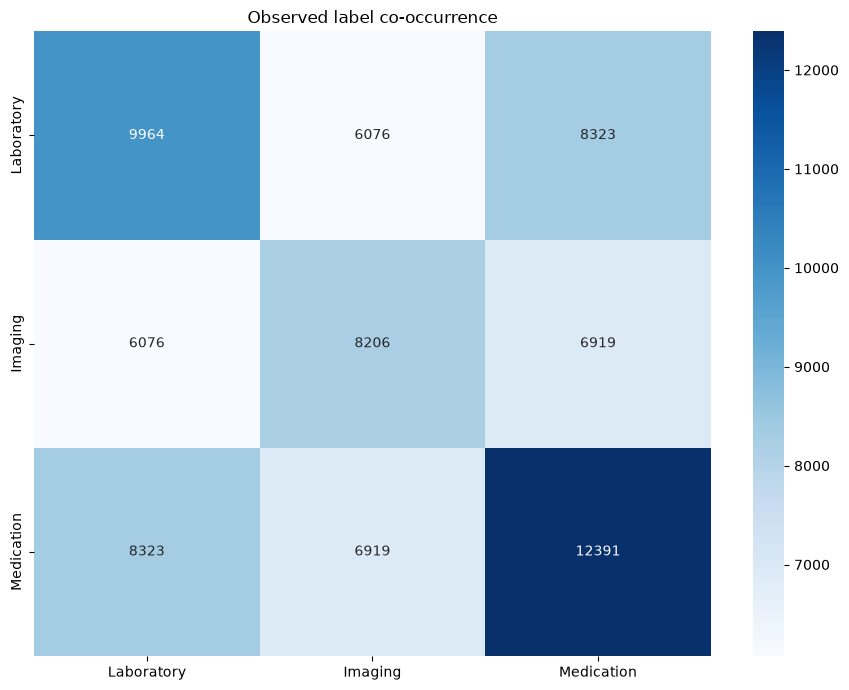

Train/test: (12018, 79) (4007, 79)


In [47]:
if not (CONFIRM_TARGET_CODES and CONFIRM_FEATURE_TIMING):
    raise RuntimeError('Complete audits in Sections 4–5 before benchmarking.')
co=Y.T.dot(Y)
display(co)
plt.figure(figsize=(9,7));sns.heatmap(co,annot=True,fmt='d',cmap='Blues');plt.title('Observed label co-occurrence');plt.tight_layout();plt.show()
# Simple random split. For publication, consider iterative multilabel stratification and grouped hospital splits.
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.25,random_state=SEED)
pre=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num_cols),
 ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_cols)
],remainder='drop',sparse_threshold=0)
Xtr=pre.fit_transform(X_train)
Xte=pre.transform(X_test)
print('Train/test:',Xtr.shape,Xte.shape)


## 7. Four multi-label baselines for three grouped outputs
Binary Relevance is the independent-label baseline; Classifier Chains models label dependencies; RAkELd is configured with all three labels in one set, making it effectively a Label Powerset baseline here; ML-kNN predicts from nearby examples using smoothed label-neighbor frequencies.


In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import NearestNeighbors

class ModernMLkNN:
    """ML-kNN with sklearn's keyword-only NearestNeighbors API."""
    def __init__(self, k=5, s=1.0):
        self.k = k
        self.s = s

    def fit(self, X, y):
        X = csr_matrix(X) if not issparse(X) else X.tocsr()
        y = csr_matrix(y, dtype=np.int8) if not issparse(y) else y.tocsr().astype(np.int8)
        self.y_train_ = y.toarray()
        n_samples, n_labels = self.y_train_.shape
        if n_samples < 2:
            raise ValueError('ML-kNN needs at least two training rows.')
        if not np.isin(self.y_train_, [0, 1]).all():
            raise ValueError('ML-kNN expects binary 0/1 target labels.')
        self.k_ = min(int(self.k), n_samples - 1)
        self.nn_ = NearestNeighbors(n_neighbors=min(self.k_ + 1, n_samples), metric='minkowski', p=2)
        self.nn_.fit(X)

        # Count positive labels among each training row's k nearest *other* rows.
        neighbor_ids = self.nn_.kneighbors(X, return_distance=False)
        neighbor_counts = np.zeros((n_samples, n_labels), dtype=np.int32)
        for i, ids in enumerate(neighbor_ids):
            ids = ids[ids != i][:self.k_]
            neighbor_counts[i] = self.y_train_[ids].sum(axis=0)

        self.prior_ = self.y_train_.mean(axis=0)
        self.conditional_ = np.zeros((n_labels, 2, self.k_ + 1), dtype=float)
        for j in range(n_labels):
            for label_value in (0, 1):
                hist = np.bincount(
                    neighbor_counts[self.y_train_[:, j] == label_value, j],
                    minlength=self.k_ + 1,
                )[:self.k_ + 1]
                self.conditional_[j, label_value] = (hist + self.s) / (hist.sum() + self.s * (self.k_ + 1))
        return self

    def predict(self, X):
        X = csr_matrix(X) if not issparse(X) else X.tocsr()
        ids = self.nn_.kneighbors(X, n_neighbors=self.k_, return_distance=False)
        neighbor_counts = self.y_train_[ids].sum(axis=1).astype(int)
        n_samples = neighbor_counts.shape[0]
        pred = np.zeros((n_samples, self.y_train_.shape[1]), dtype=np.int8)
        for j in range(self.y_train_.shape[1]):
            count = neighbor_counts[:, j]
            p_absent = (1 - self.prior_[j]) * self.conditional_[j, 0, count]
            p_present = self.prior_[j] * self.conditional_[j, 1, count]
            pred[:, j] = (p_present > p_absent).astype(np.int8)
        return pred

base=LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED)
models={
 'Binary Relevance':OneVsRestClassifier(clone(base)),
 'Classifier Chains':ClassifierChain(estimator=clone(base),order='random',random_state=SEED),
 # Three labels in one set avoids an uneven 2+1 RAkELd partition; this is
 # effectively a Label Powerset baseline for the current three grouped outputs.
 'RAkELd':RakelD(base_classifier=DecisionTreeClassifier(max_depth=8,min_samples_leaf=5,random_state=SEED),labelset_size=Y.shape[1]),
 'ML-kNN':ModernMLkNN(k=5,s=1.0),
}
results=[]; fitted={}; predictions={}
for name,model in models.items():
    print('Training',name)
    try:
        if name in ('RAkELd','ML-kNN'):
            model.fit(csr_matrix(Xtr),csr_matrix(Y_train.to_numpy()))
            pred=model.predict(csr_matrix(Xte))
        else:
            model.fit(Xtr,Y_train.to_numpy())
            pred=model.predict(Xte)
        pred=pred.toarray() if issparse(pred) else np.asarray(pred)
        pred=np.asarray(pred,dtype=int)
        if pred.shape != Y_test.shape: raise ValueError(f'Unexpected prediction shape: {pred.shape}')
        predictions[name]=pred;fitted[name]=model
        results.append({'Model':name,'F1 micro':f1_score(Y_test,pred,average='micro',zero_division=0),
         'F1 macro':f1_score(Y_test,pred,average='macro',zero_division=0),
         'F1 samples':f1_score(Y_test,pred,average='samples',zero_division=0),
         'Hamming loss':hamming_loss(Y_test,pred),
         'Subset accuracy':np.mean(np.all(Y_test.to_numpy()==pred,axis=1))})
    except Exception as e:
        import traceback
        print(f'{name}: FAILED ({type(e).__name__}: {e})')
        traceback.print_exc()
metrics=pd.DataFrame(results).sort_values('F1 micro',ascending=False)
display(metrics)
metrics.to_csv(OUT/'benchmark_metrics.csv',index=False)


Training Binary Relevance
Training Classifier Chains
Training RAkELd
Training ML-kNN


,Model,F1 micro,F1 macro,F1 samples,Hamming loss,Subset accuracy
2,RAkELd,0.780066,0.764079,0.692538,0.304717,0.368855
3,ML-kNN,0.774514,0.748589,0.706954,0.317361,0.332917
0,Binary Relevance,0.688010,0.686769,0.498661,0.362366,0.303469
1,Classifier Chains,0.681723,0.681228,0.452541,0.368106,0.317694


## 8. Per-output results and output relationships

In [49]:
for model_name,pred in predictions.items():
    print('\n',model_name)
    report=classification_report(Y_test,pred,target_names=Y.columns.tolist(),output_dict=True,zero_division=0)
    display(pd.DataFrame(report).T.loc[list(Y.columns),['precision','recall','f1-score','support']].round(3))



 Binary Relevance


,precision,recall,f1-score,support
Laboratory,0.766,0.670,0.715,2497.0
Imaging,0.675,0.648,0.661,2023.0
Medication,0.832,0.582,0.685,3128.0



 Classifier Chains


,precision,recall,f1-score,support
Laboratory,0.766,0.670,0.715,2497.0
Imaging,0.671,0.651,0.661,2023.0
Medication,0.829,0.560,0.668,3128.0



 RAkELd


,precision,recall,f1-score,support
Laboratory,0.716,0.795,0.753,2497.0
Imaging,0.615,0.728,0.667,2023.0
Medication,0.791,0.972,0.872,3128.0



 ML-kNN


,precision,recall,f1-score,support
Laboratory,0.668,0.892,0.764,2497.0
Imaging,0.613,0.592,0.602,2023.0
Medication,0.785,1.000,0.880,3128.0


## 9. Explainability with SHAP — one of the three output labels
Explain the **Binary Relevance logistic model** (if successfully trained). SHAP values describe associations *within the fitted predictive model*, not medical causality.

SHAP label: Laboratory


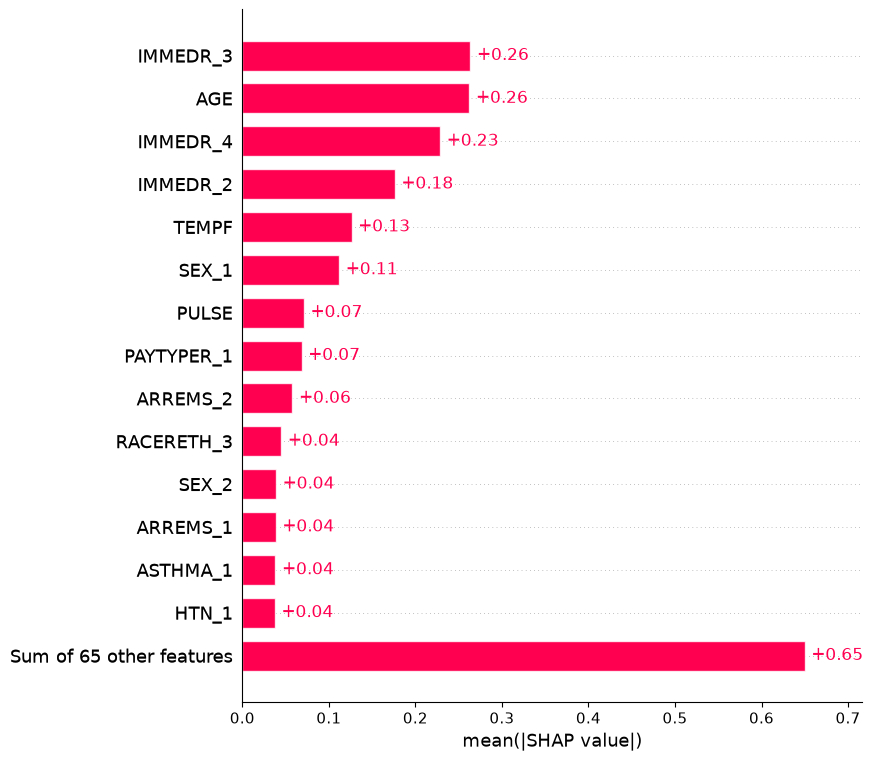

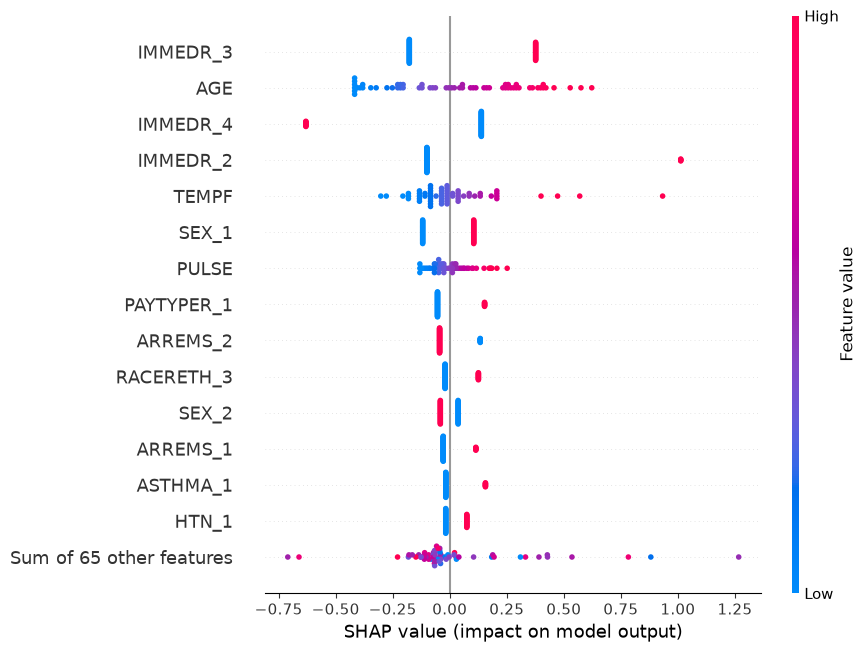

In [50]:
import shap
if 'Binary Relevance' not in fitted:
    print('Binary Relevance unavailable; skip SHAP.')
else:
    model=fitted['Binary Relevance']
    LABEL_TO_EXPLAIN=Y.columns[0]
    idx=list(Y.columns).index(LABEL_TO_EXPLAIN)
    estimator=model.estimators_[idx]
    # Keep names from the fitted preprocessor so SHAP does not show generic
    # feature indices. One-hot columns appear as e.g. SEX_1 or IMMEDR_3.
    feature_names=[name.replace('num__','').replace('cat__','')
                   for name in pre.get_feature_names_out()]
    # Linear logistic coefficients can be explained with SHAP LinearExplainer.
    background=pd.DataFrame(Xtr[:min(100,len(Xtr))], columns=feature_names)
    sample=pd.DataFrame(Xte[:min(60,len(Xte))], columns=feature_names)
    explainer=shap.LinearExplainer(estimator,background)
    values=explainer(sample)
    print('SHAP label:',LABEL_TO_EXPLAIN)
    shap.plots.bar(values,max_display=15,show=True)
    shap.plots.beeswarm(values,max_display=15,show=True)


## 10. Save audit and model artifacts

In [51]:
if CONFIRM_TARGET_CODES and CONFIRM_FEATURE_TIMING and results:
    joblib.dump({
        'preprocessor': pre,
        'models': {k: v for k, v in fitted.items() if k not in ('RAkELd', 'ML-kNN')},
        'labels': Y.columns.tolist(),
        'features': feature_cols,
    }, OUT / 'models.pkl')
    pd.DataFrame({
        'label': Y.columns,
        'source_columns': [', '.join(resolved[x]) for x in Y.columns],
        'prevalence': Y.mean().values,
    }).to_csv(OUT / 'target_audit.csv', index=False)
    print('Saved to', OUT.resolve())
else:
    print('Skipped — audit and modeling need completion.')


Saved to /Users/maroqijalil/Documents/_Bismillah Double Degree ITSxNTUST/Term 1/Kecerdasan Komputasional/final-project/ed-multilabel-prediction/outputs


## Research-validity checklist

- The three targets are broad visit-level groups: any selected laboratory service, any selected imaging service, and medication given/prescribed (`MED`). Laboratory and imaging outcomes do not retain specific service detail.
- Verify every component code and missing value against the 2022 codebook. In particular, `MED=2` means the medication item is entirely blank, not “No.”
- Survey test fields indicate services ordered or provided and do not identify order time. This retrospective benchmark does not establish prediction at triage.
- Medication given/prescribed is a distinct outcome from diagnostic orders. Specific medications would require a separately documented target built from medication fields.
- To claim triage-time prediction, only include variables genuinely available then. Downstream diagnoses, disposition, and potentially injury/context fields can cause leakage.
- NHAMCS is a complex survey. Unweighted model performance is not automatically nationally representative; use sampling weights/design variables for population-level inference.
- SHAP explains model behavior, not medical causality or whether a service should be ordered.
- External/temporal validation and clinical review are needed before prospective claims.
